# Gold Price Forecasting — USD/oz

## Project objective

Forecast the monthly gold price in **USD per troy ounce** from **October 2026 to September 2027**.

The workflow compares:
- Naive and Seasonal Naive baselines
- ARIMA
- XGBoost on price
- XGBoost on monthly returns
- LSTM
- GRU

Model selection is based on **rolling-origin time-series cross-validation** with 5 validation windows of 12 months.

> **Important:** Split 5 ends in September 2026 and was used during model comparison. It is therefore **not an untouched final test set**.

## 1. Imports

In [1]:
import os
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

## 2. Load and clean the dataset

In [2]:
# Search for the CSV in common project locations.
candidate_paths = [
    Path("gold_monthly_avg.csv"),
    Path("../gold_monthly_avg.csv"),
    Path("../data/gold_monthly_avg.csv"),
    Path("data/gold_monthly_avg.csv"),
]

data_path = next((p for p in candidate_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "gold_monthly_avg.csv not found. "
        "Place it in the project root or in data/."
    )

raw = pd.read_csv(data_path, header=None)

columns = [
    "Date","USD","EUR","JPY","GBP","CAD","CHF","INR","CNY","TRY",
    "SAR","IDR","AED","THB","VND","EGP","KRW","RUB","ZAR","AUD"
]

gold = raw.iloc[5:, 2:22].copy()
gold.columns = columns
gold = gold.reset_index(drop=True)

gold["Date"] = pd.to_datetime(gold["Date"], errors="coerce")

for col in columns[1:]:
    gold[col] = pd.to_numeric(gold[col], errors="coerce")

gold = gold.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)

print("Shape:", gold.shape)
print("Period:", gold["Date"].min(), "→", gold["Date"].max())
print("Duplicate dates:", gold["Date"].duplicated().sum())
print("Dates increasing:", gold["Date"].is_monotonic_increasing)
print("Missing USD:", gold["USD"].isna().sum())

Shape: (585, 20)
Period: 1978-01-31 00:00:00 → 2026-09-30 00:00:00
Duplicate dates: 0
Dates increasing: True
Missing USD: 0


In [3]:
print(gold.head())
print(gold.tail())
print(gold[["Date", "USD"]].describe())

        Date     USD        EUR          JPY        GBP        CAD        CHF  \
0 1978-01-31  207.83  129.20810          NaN  104.62599        NaN        NaN   
1 1978-02-28  227.27  139.53296  44853.10621  113.32103  269.54823  378.77281   
2 1978-03-31  245.67  151.30799  49213.15041  122.54972  293.17263  410.58371   
3 1978-04-28  242.05  149.30073  49989.43254  118.79066  284.20489  407.26165   
4 1978-05-31  239.16  148.76416  51707.16895  115.43299  274.23889  410.50434   

   INR  CNY  TRY        SAR           IDR        AED         THB  VND  EGP  \
0  NaN  NaN  NaN        NaN           NaN        NaN         NaN  NaN  NaN   
1  NaN  NaN  NaN  754.08837  141796.36585  869.39601  4582.17775  NaN  NaN   
2  NaN  NaN  NaN  822.30530  153099.59140  939.09373  4949.49689  NaN  NaN   
3  NaN  NaN  NaN  810.13899  151068.54230  926.22479  4884.52856  NaN  NaN   
4  NaN  NaN  NaN  817.29641  149744.25491  919.93608  4842.57197  NaN  NaN   

            KRW  RUB        ZAR        AUD  

## 3. Exploratory Data Analysis

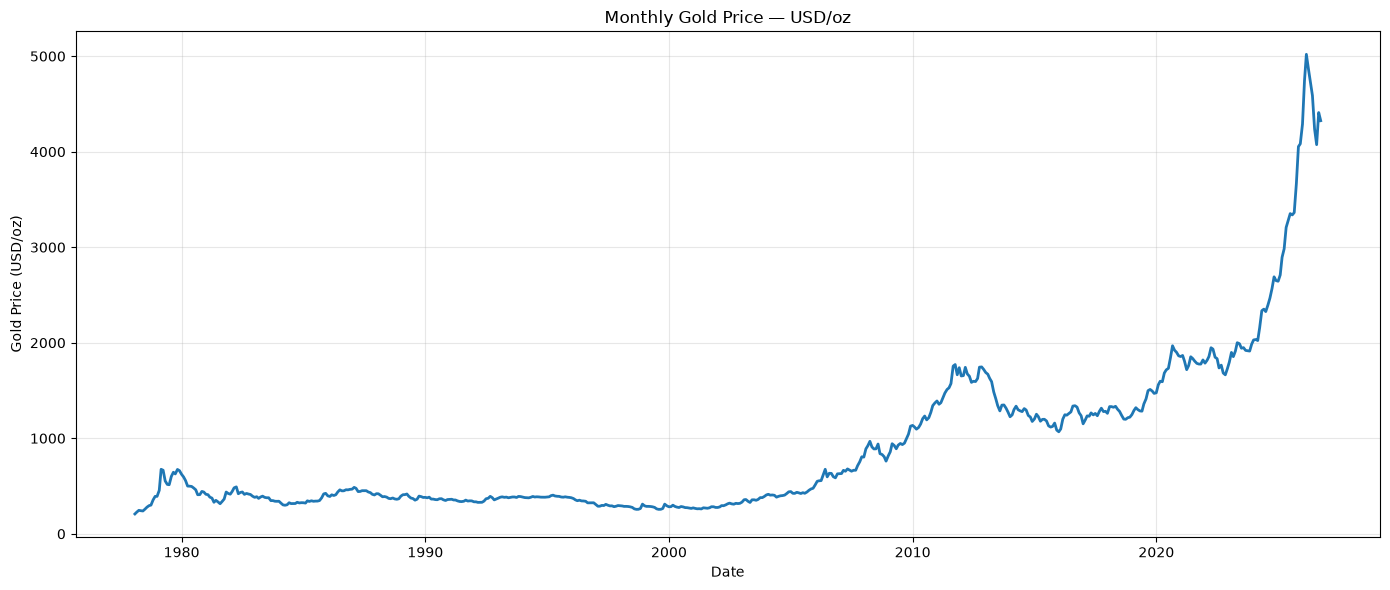

In [4]:
plt.figure(figsize=(14, 6))
plt.plot(gold["Date"], gold["USD"], linewidth=2)
plt.title("Monthly Gold Price — USD/oz")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD/oz)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

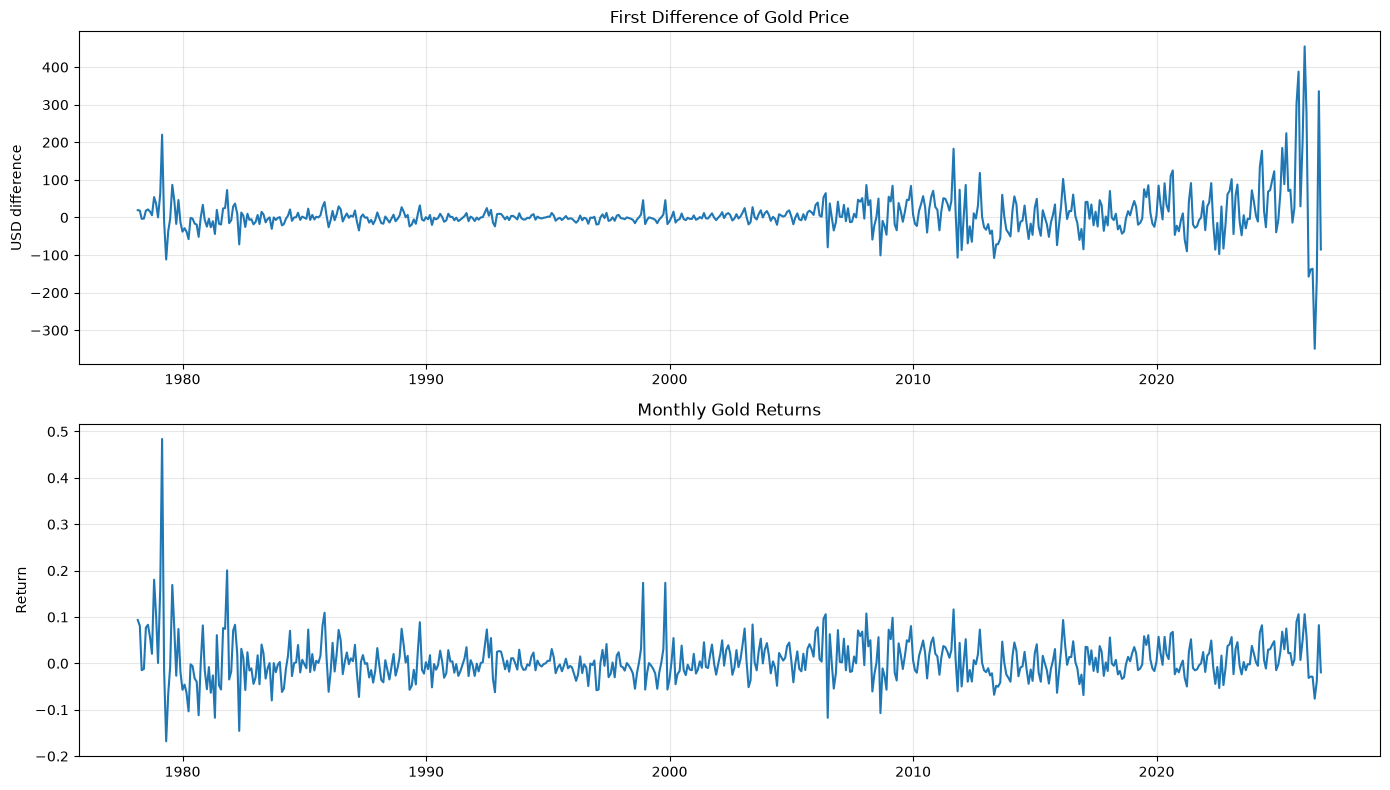

In [5]:
gold["USD_diff"] = gold["USD"].diff()
gold["USD_return"] = gold["USD"].pct_change()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(gold["Date"], gold["USD_diff"])
axes[0].set_title("First Difference of Gold Price")
axes[0].set_ylabel("USD difference")
axes[0].grid(True, alpha=0.3)

axes[1].plot(gold["Date"], gold["USD_return"])
axes[1].set_title("Monthly Gold Returns")
axes[1].set_ylabel("Return")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
peak = gold.loc[gold["USD"].idxmax(), ["Date", "USD"]]
last = gold.iloc[-1][["Date", "USD"]]

print("Historical peak:")
print(peak)
print("\nLast observation:")
print(last)

Historical peak:
Date    2026-02-27 00:00:00
USD                 5019.53
Name: 577, dtype: object

Last observation:
Date    2026-09-30 00:00:00
USD                 4324.72
Name: 584, dtype: object


## 4. Stationarity analysis

In [7]:
def adf_result(series, name):
    result = adfuller(series.dropna())
    print(f"{name}: ADF p-value = {result[1]:.10g}")

adf_result(gold["USD"], "USD level")
adf_result(gold["USD_diff"], "First difference")
adf_result(gold["USD_return"], "Monthly return")

USD level: ADF p-value = 0.9976010129
First difference: ADF p-value = 7.025974033e-05
Monthly return: ADF p-value = 4.698139502e-24


The original USD price is non-stationary, while the first difference and monthly returns are stationary.

For the machine-learning models, the target is therefore the **monthly return**, which is converted recursively back into the price level.

## 5. Time-series validation setup

In [8]:
tscv = TimeSeriesSplit(n_splits=5, test_size=12)

for split, (train_idx, val_idx) in enumerate(tscv.split(gold), start=1):
    print(
        f"Split {split}: "
        f"train {gold['Date'].iloc[train_idx[0]].date()} → {gold['Date'].iloc[train_idx[-1]].date()} | "
        f"validation {gold['Date'].iloc[val_idx[0]].date()} → {gold['Date'].iloc[val_idx[-1]].date()}"
    )

Split 1: train 1978-01-31 → 2021-09-30 | validation 2021-10-29 → 2022-09-30
Split 2: train 1978-01-31 → 2022-09-30 | validation 2022-10-31 → 2023-09-29
Split 3: train 1978-01-31 → 2023-09-29 | validation 2023-10-31 → 2024-09-30
Split 4: train 1978-01-31 → 2024-09-30 | validation 2024-10-31 → 2025-09-30
Split 5: train 1978-01-31 → 2025-09-30 | validation 2025-10-31 → 2026-09-30


## 6. Naive baseline

In [9]:
naive_results = []

for split, (train_idx, val_idx) in enumerate(tscv.split(gold), start=1):
    train = gold.iloc[train_idx]
    val = gold.iloc[val_idx]

    predicted = np.repeat(train["USD"].iloc[-1], len(val))
    actual = val["USD"].values

    naive_results.append({
        "Split": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE": np.mean(np.abs((actual - predicted) / actual)) * 100
    })

naive_results_df = pd.DataFrame(naive_results)
print(naive_results_df.round(2))
print("\nMean:")
print(naive_results_df[["MAE", "RMSE", "MAPE"]].mean().round(2))

   Split     MAE    RMSE   MAPE
0      1   64.41   82.83   3.48
1      2  201.19  221.41  10.46
2      3  299.30  363.74  12.75
3      4  497.59  598.21  15.25
4      5  785.64  846.72  17.24

Mean:
MAE     369.63
RMSE    422.58
MAPE     11.83
dtype: float64


## 7. Seasonal Naive baseline

In [10]:
seasonal_results = []

for split, (train_idx, val_idx) in enumerate(tscv.split(gold), start=1):
    train = gold.iloc[train_idx]
    val = gold.iloc[val_idx]

    # Last 12 observed prices repeated for the next 12 months.
    predicted = train["USD"].iloc[-12:].values
    actual = val["USD"].values

    seasonal_results.append({
        "Split": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE": np.mean(np.abs((actual - predicted) / actual)) * 100
    })

seasonal_results_df = pd.DataFrame(seasonal_results)
print(seasonal_results_df.round(2))
print("\nMean:")
print(seasonal_results_df[["MAE", "RMSE", "MAPE"]].mean().round(2))

   Split      MAE     RMSE   MAPE
0      1    77.09   101.40   4.19
1      2   104.45   125.72   5.52
2      3   334.53   365.42  14.69
3      4   849.10   860.58  27.57
4      5  1386.14  1462.72  30.79

Mean:
MAE     550.26
RMSE    583.17
MAPE     16.55
dtype: float64


## 8. ARIMA

In [11]:
# AIC search on the first training portion.
train0, _ = next(tscv.split(gold))
train_arima = gold.iloc[train0]["USD"]

arima_candidates = []

for p in range(4):
    for q in range(4):
        try:
            fitted = ARIMA(train_arima, order=(p, 1, q)).fit()
            arima_candidates.append({
                "p": p,
                "d": 1,
                "q": q,
                "AIC": fitted.aic
            })
        except Exception:
            pass

arima_aic_df = pd.DataFrame(arima_candidates).sort_values("AIC")
print(arima_aic_df.head(10).round(3))

    p  d  q       AIC
15  3  1  3  5118.527
5   1  1  1  5119.927
6   1  1  2  5120.318
10  2  1  2  5120.473
9   2  1  1  5120.570
7   1  1  3  5120.970
2   0  1  2  5121.476
13  3  1  1  5122.058
11  2  1  3  5122.102
14  3  1  2  5122.257


In [12]:
arima_results = []

for split, (train_idx, val_idx) in enumerate(tscv.split(gold), start=1):
    train = gold.iloc[train_idx]
    val = gold.iloc[val_idx]

    model = ARIMA(train["USD"], order=(2, 1, 3)).fit()
    predicted = model.forecast(steps=len(val)).values
    actual = val["USD"].values

    arima_results.append({
        "Split": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE": np.mean(np.abs((actual - predicted) / actual)) * 100
    })

arima_results_df = pd.DataFrame(arima_results)
print(arima_results_df.round(2))
print("\nMean:")
print(arima_results_df[["MAE", "RMSE", "MAPE"]].mean().round(2))

   Split     MAE    RMSE   MAPE
0      1   63.04   80.32   3.42
1      2  241.82  265.50  12.57
2      3  287.43  350.65  12.24
3      4  473.69  577.08  14.47
4      5  406.70  498.64   8.83

Mean:
MAE     294.54
RMSE    354.44
MAPE     10.30
dtype: float64


## 9. XGBoost — direct price

In [13]:
xgb_price_results = []

price_tscv = TimeSeriesSplit(n_splits=5, test_size=12)

for split, (train_idx, val_idx) in enumerate(price_tscv.split(gold_ml), start=1):
    train_data = gold_ml.iloc[train_idx]
    val_data = gold_ml.iloc[val_idx]

    model = XGBRegressor(**xgb_params)
    model.fit(train_data[price_features], train_data["USD"])

    predicted_prices = []
    history_prices = list(train_data["USD"].values)

    for _, row in val_data.iterrows():
        hist = pd.Series(history_prices)

        X_future = pd.DataFrame([{
            "lag_1": hist.iloc[-1],
            "lag_2": hist.iloc[-2],
            "lag_3": hist.iloc[-3],
            "lag_6": hist.iloc[-6],
            "lag_12": hist.iloc[-12],
            "rolling_mean_3": hist.iloc[-3:].mean(),
            "rolling_mean_6": hist.iloc[-6:].mean(),
            "rolling_mean_12": hist.iloc[-12:].mean(),
            "rolling_std_3": hist.iloc[-3:].std(),
            "rolling_std_6": hist.iloc[-6:].std(),
            "rolling_std_12": hist.iloc[-12:].std(),
            "month": row["Date"].month
        }])

        pred = model.predict(X_future)[0]
        predicted_prices.append(pred)
        history_prices.append(pred)

    actual = val_data["USD"].values
    predicted = np.array(predicted_prices)

    xgb_price_results.append({
        "Split": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE": np.mean(np.abs((actual - predicted) / actual)) * 100
    })

xgb_price_results_df = pd.DataFrame(xgb_price_results)

print(xgb_price_results_df.round(2))
print("\nMean:")
print(xgb_price_results_df[["MAE", "RMSE", "MAPE"]].mean().round(2))


NameError: name 'gold_ml' is not defined

In [ ]:
xgb_price_results = []

price_tscv = TimeSeriesSplit(n_splits=5, test_size=12)

for split, (train_idx, val_idx) in enumerate(price_tscv.split(gold_ml), start=1):
    train_data = gold_ml.iloc[train_idx]
    val_data = gold_ml.iloc[val_idx]

    model = XGBRegressor(**xgb_params)
    model.fit(train_data[price_features], train_data["USD"])

    predicted_prices = []
    history = train_data[["Date", "USD"]].copy()

    for _, row in val_data.iterrows():
        hist = history["USD"]

        X_future = pd.DataFrame([{
            "lag_1": hist.iloc[-1],
            "lag_2": hist.iloc[-2],
            "lag_3": hist.iloc[-3],
            "lag_6": hist.iloc[-6],
            "lag_12": hist.iloc[-12],
            "rolling_mean_3": hist.iloc[-3:].mean(),
            "rolling_mean_6": hist.iloc[-6:].mean(),
            "rolling_mean_12": hist.iloc[-12:].mean(),
            "rolling_std_3": hist.iloc[-3:].std(),
            "rolling_std_6": hist.iloc[-6:].std(),
            "rolling_std_12": hist.iloc[-12:].std(),
            "month": row["Date"].month
        }])

        pred = model.predict(X_future)[0]
        predicted_prices.append(pred)

        history = pd.concat([
            history,
            pd.Series([pred], index=history.index[-1:] + 1)
        ], ignore_index=True)

    actual = val_data["USD"].values
    predicted = np.array(predicted_prices)

    xgb_price_results.append({
        "Split": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE": np.mean(np.abs((actual - predicted) / actual)) * 100
    })

xgb_price_results_df = pd.DataFrame(xgb_price_results)
print(xgb_price_results_df.round(2))
print("\nMean:")
print(xgb_price_results_df[["MAE", "RMSE", "MAPE"]].mean().round(2))

## 10. XGBoost — monthly returns

In [ ]:
gold_return = gold[["Date", "USD"]].copy()
gold_return["return"] = gold_return["USD"].pct_change()

for lag in [1, 2, 3, 6, 12]:
    gold_return[f"return_lag_{lag}"] = gold_return["return"].shift(lag)

for window in [3, 6, 12]:
    shifted = gold_return["return"].shift(1)
    gold_return[f"return_mean_{window}"] = shifted.rolling(window).mean()
    gold_return[f"return_std_{window}"] = shifted.rolling(window).std()

gold_return["month"] = gold_return["Date"].dt.month
gold_return = gold_return.dropna().reset_index(drop=True)

return_features = [
    "return_lag_1", "return_lag_2", "return_lag_3",
    "return_lag_6", "return_lag_12",
    "return_mean_3", "return_mean_6", "return_mean_12",
    "return_std_3", "return_std_6", "return_std_12",
    "month"
]

print("Shape:", gold_return.shape)

In [ ]:
def recursive_xgb_return_cv(params):
    results = []
    split5 = None

    for split, (train_idx, val_idx) in enumerate(
        TimeSeriesSplit(n_splits=5, test_size=12).split(gold_return), 1
    ):
        train_data = gold_return.iloc[train_idx]
        val_data = gold_return.iloc[val_idx]

        model = XGBRegressor(**params)
        model.fit(train_data[return_features], train_data["return"])

        history = train_data[["Date", "USD", "return"]].copy()
        predicted_prices = []

        for _, row in val_data.iterrows():
            r = history["return"]

            X_future = pd.DataFrame([{
                "return_lag_1": r.iloc[-1],
                "return_lag_2": r.iloc[-2],
                "return_lag_3": r.iloc[-3],
                "return_lag_6": r.iloc[-6],
                "return_lag_12": r.iloc[-12],
                "return_mean_3": r.iloc[-3:].mean(),
                "return_mean_6": r.iloc[-6:].mean(),
                "return_mean_12": r.iloc[-12:].mean(),
                "return_std_3": r.iloc[-3:].std(),
                "return_std_6": r.iloc[-6:].std(),
                "return_std_12": r.iloc[-12:].std(),
                "month": row["Date"].month
            }])

            pred_return = model.predict(X_future)[0]
            previous_price = history["USD"].iloc[-1]
            pred_price = previous_price * (1 + pred_return)

            predicted_prices.append(pred_price)

            history = pd.concat([
                history,
                pd.DataFrame([{
                    "Date": row["Date"],
                    "USD": pred_price,
                    "return": pred_return
                }])
            ], ignore_index=True)

        actual = val_data["USD"].values
        predicted = np.array(predicted_prices)

        results.append({
            "Split": split,
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "MAPE": np.mean(np.abs((actual - predicted) / actual)) * 100
        })

        if split == 5:
            split5 = pd.DataFrame({
                "Date": val_data["Date"].values,
                "Actual": actual,
                "XGBoost_Return": predicted
            })

    return pd.DataFrame(results), split5


xgb_return_results_df, split5_xgb = recursive_xgb_return_cv(xgb_params)

print(xgb_return_results_df.round(2))
print("\nMean:")
print(xgb_return_results_df[["MAE", "RMSE", "MAPE"]].mean().round(2))

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(split5_xgb["Date"], split5_xgb["Actual"], marker="o", label="Actual")
plt.plot(split5_xgb["Date"], split5_xgb["XGBoost_Return"], marker="o", label="XGBoost Return")
plt.title("XGBoost Return — Split 5")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD/oz)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. XGBoost tuning

In [ ]:
param_configs = [
    {
        "name": "Baseline",
        **xgb_params
    },
    {
        "name": "Shallow",
        **xgb_params,
        "n_estimators": 500,
        "max_depth": 2,
        "learning_rate": 0.03
    },
    {
        "name": "Deeper",
        **xgb_params,
        "max_depth": 4
    },
    {
        "name": "Regularized",
        **xgb_params,
        "n_estimators": 400,
        "learning_rate": 0.03,
        "min_child_weight": 3
    },
    {
        "name": "MoreSamples",
        **xgb_params,
        "n_estimators": 400,
        "learning_rate": 0.03,
        "subsample": 1.0,
        "colsample_bytree": 1.0
    }
]

tuning_rows = []

for config in param_configs:
    name = config.pop("name")
    result_df, _ = recursive_xgb_return_cv(config)
    mean_metrics = result_df[["MAE", "RMSE", "MAPE"]].mean()

    tuning_rows.append({
        "Model": name,
        "MAE": mean_metrics["MAE"],
        "RMSE": mean_metrics["RMSE"],
        "MAPE": mean_metrics["MAPE"]
    })

    config["name"] = name

tuning_results_df = pd.DataFrame(tuning_rows).sort_values("MAE")
print(tuning_results_df.round(2))

## 12. LSTM

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

lstm_raw = gold[["Date", "USD"]].copy()
lstm_raw["return"] = lstm_raw["USD"].pct_change()
lstm_raw = lstm_raw.dropna().reset_index(drop=True)

lstm_returns = lstm_raw["return"].values
lstm_prices = lstm_raw["USD"].values
lstm_dates = lstm_raw["Date"].values

sequence_length = 12

def create_sequences(data, sequence_length=12):
    X, y = [], []
    for i in range(sequence_length, len(data)):
        X.append(data[i-sequence_length:i])
        y.append(data[i])
    return np.array(X), np.array(y)

def build_lstm(sequence_length=12):
    model = Sequential([
        LSTM(32, input_shape=(sequence_length, 1)),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

In [ ]:
lstm_results = []
split5_lstm = None

for split, (train_idx, val_idx) in enumerate(
    TimeSeriesSplit(n_splits=5, test_size=12).split(lstm_returns), 1
):
    train_returns = lstm_returns[train_idx]

    scaler = StandardScaler()
    scaler.fit(train_returns.reshape(-1, 1))

    train_scaled = scaler.transform(
        train_returns.reshape(-1, 1)
    ).ravel()

    X_train, y_train = create_sequences(train_scaled, sequence_length)
    X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)

    validation_size = 12
    X_fit, y_fit = X_train[:-validation_size], y_train[:-validation_size]
    X_internal, y_internal = X_train[-validation_size:], y_train[-validation_size:]

    tf.keras.utils.set_random_seed(SEED)
    model = build_lstm(sequence_length)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    model.fit(
        X_fit, y_fit,
        validation_data=(X_internal, y_internal),
        epochs=100,
        batch_size=16,
        callbacks=[early_stop],
        shuffle=False,
        verbose=0
    )

    history = list(train_returns[-sequence_length:])
    current_price = lstm_prices[train_idx[-1]]
    predicted_prices = []

    for _ in range(len(val_idx)):
        input_scaled = scaler.transform(
            np.array(history[-sequence_length:]).reshape(-1, 1)
        ).reshape(1, sequence_length, 1)

        pred_scaled = model.predict(input_scaled, verbose=0)[0, 0]
        pred_return = scaler.inverse_transform([[pred_scaled]])[0, 0]

        current_price *= (1 + pred_return)
        predicted_prices.append(current_price)

        history.append(pred_return)

    actual_prices = lstm_prices[val_idx]
    predicted_prices = np.array(predicted_prices)

    lstm_results.append({
        "Split": split,
        "MAE": mean_absolute_error(actual_prices, predicted_prices),
        "RMSE": np.sqrt(mean_squared_error(actual_prices, predicted_prices)),
        "MAPE": np.mean(np.abs((actual_prices - predicted_prices) / actual_prices)) * 100
    })

    if split == 5:
        split5_lstm = pd.DataFrame({
            "Date": lstm_dates[val_idx],
            "Actual": actual_prices,
            "LSTM": predicted_prices
        })

lstm_results_df = pd.DataFrame(lstm_results)

print(lstm_results_df.round(2))
print("\nMean:")
print(lstm_results_df[["MAE", "RMSE", "MAPE"]].mean().round(2))

## 13. GRU

In [ ]:
from tensorflow.keras.layers import GRU

def build_gru(sequence_length=12):
    model = Sequential([
        GRU(32, input_shape=(sequence_length, 1)),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")
    return model

In [ ]:
gru_results = []
split5_gru = None

for split, (train_idx, val_idx) in enumerate(
    TimeSeriesSplit(n_splits=5, test_size=12).split(lstm_returns), 1
):
    train_returns = lstm_returns[train_idx]

    scaler = StandardScaler()
    scaler.fit(train_returns.reshape(-1, 1))

    train_scaled = scaler.transform(
        train_returns.reshape(-1, 1)
    ).ravel()

    X_train, y_train = create_sequences(train_scaled, sequence_length)
    X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)

    validation_size = 12
    X_fit, y_fit = X_train[:-validation_size], y_train[:-validation_size]
    X_internal, y_internal = X_train[-validation_size:], y_train[-validation_size:]

    tf.keras.utils.set_random_seed(SEED)
    model = build_gru(sequence_length)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    model.fit(
        X_fit, y_fit,
        validation_data=(X_internal, y_internal),
        epochs=100,
        batch_size=16,
        callbacks=[early_stop],
        shuffle=False,
        verbose=0
    )

    history = list(train_returns[-sequence_length:])
    current_price = lstm_prices[train_idx[-1]]
    predicted_prices = []

    for _ in range(len(val_idx)):
        input_scaled = scaler.transform(
            np.array(history[-sequence_length:]).reshape(-1, 1)
        ).reshape(1, sequence_length, 1)

        pred_scaled = model.predict(input_scaled, verbose=0)[0, 0]
        pred_return = scaler.inverse_transform([[pred_scaled]])[0, 0]

        current_price *= (1 + pred_return)
        predicted_prices.append(current_price)

        history.append(pred_return)

    actual_prices = lstm_prices[val_idx]
    predicted_prices = np.array(predicted_prices)

    gru_results.append({
        "Split": split,
        "MAE": mean_absolute_error(actual_prices, predicted_prices),
        "RMSE": np.sqrt(mean_squared_error(actual_prices, predicted_prices)),
        "MAPE": np.mean(np.abs((actual_prices - predicted_prices) / actual_prices)) * 100
    })

    if split == 5:
        split5_gru = pd.DataFrame({
            "Date": lstm_dates[val_idx],
            "Actual": actual_prices,
            "GRU": predicted_prices
        })

gru_results_df = pd.DataFrame(gru_results)

print(gru_results_df.round(2))
print("\nMean:")
print(gru_results_df[["MAE", "RMSE", "MAPE"]].mean().round(2))

## 14. Final model comparison

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive",
        "ARIMA(2,1,3)",
        "XGBoost Direct Price",
        "XGBoost Return",
        "LSTM",
        "GRU"
    ],
    "MAE": [
        naive_results_df["MAE"].mean(),
        seasonal_results_df["MAE"].mean(),
        arima_results_df["MAE"].mean(),
        xgb_price_results_df["MAE"].mean(),
        xgb_return_results_df["MAE"].mean(),
        lstm_results_df["MAE"].mean(),
        gru_results_df["MAE"].mean()
    ],
    "RMSE": [
        naive_results_df["RMSE"].mean(),
        seasonal_results_df["RMSE"].mean(),
        arima_results_df["RMSE"].mean(),
        xgb_price_results_df["RMSE"].mean(),
        xgb_return_results_df["RMSE"].mean(),
        lstm_results_df["RMSE"].mean(),
        gru_results_df["RMSE"].mean()
    ],
    "MAPE": [
        naive_results_df["MAPE"].mean(),
        seasonal_results_df["MAPE"].mean(),
        arima_results_df["MAPE"].mean(),
        xgb_price_results_df["MAPE"].mean(),
        xgb_return_results_df["MAPE"].mean(),
        lstm_results_df["MAPE"].mean(),
        gru_results_df["MAPE"].mean()
    ]
}).sort_values("MAE").reset_index(drop=True)

comparison.round(2)


In [ ]:
comparison.to_csv("model_comparison.csv", index=False)

plt.figure(figsize=(10, 5))
plot_df = comparison.sort_values("MAE")

plt.bar(plot_df["Model"], plot_df["MAE"])
plt.ylabel("Mean MAE (USD)")
plt.xlabel("Model")
plt.title("Model Comparison — Mean MAE")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### Model selection

**XGBoost Return** is selected as the final model.

It achieved the lowest average **MAE (196.07 USD)** and **MAPE (6.55%)**. LSTM achieved a slightly lower RMSE, but XGBoost performed better on MAE and MAPE and was therefore preferred overall.

The model uses monthly returns, lagged returns, rolling statistics and the month of the year.

## 15. Train the final XGBoost model on all available data

In [ ]:
final_model = XGBRegressor(**xgb_params)
final_model.fit(gold_return[return_features], gold_return["return"])

print("Final model trained.")
print("Last available date:", gold["Date"].iloc[-1])
print("Last actual price:", gold["USD"].iloc[-1])

## 16. Final forecast — October 2026 to September 2027

In [ ]:
future_dates = pd.date_range(
    start="2026-10-31",
    periods=12,
    freq="ME"
)

history = gold_return[["Date", "USD", "return"]].copy()
forecast_rows = []

for date in future_dates:
    r = history["return"]

    X_future = pd.DataFrame([{
        "return_lag_1": r.iloc[-1],
        "return_lag_2": r.iloc[-2],
        "return_lag_3": r.iloc[-3],
        "return_lag_6": r.iloc[-6],
        "return_lag_12": r.iloc[-12],
        "return_mean_3": r.iloc[-3:].mean(),
        "return_mean_6": r.iloc[-6:].mean(),
        "return_mean_12": r.iloc[-12:].mean(),
        "return_std_3": r.iloc[-3:].std(),
        "return_std_6": r.iloc[-6:].std(),
        "return_std_12": r.iloc[-12:].std(),
        "month": date.month
    }])

    predicted_return = final_model.predict(X_future)[0]
    previous_price = history["USD"].iloc[-1]
    predicted_price = previous_price * (1 + predicted_return)

    forecast_rows.append({
        "Date": date,
        "Predicted_Return": predicted_return,
        "Predicted_USD": predicted_price
    })

    history = pd.concat([
        history,
        pd.DataFrame([{
            "Date": date,
            "USD": predicted_price,
            "return": predicted_return
        }])
    ], ignore_index=True)

forecast_df = pd.DataFrame(forecast_rows)

print(forecast_df.round(2))

last_price = gold["USD"].iloc[-1]
final_price = forecast_df["Predicted_USD"].iloc[-1]
change_pct = (final_price / last_price - 1) * 100

print(f"\nLast actual price: {last_price:.2f} USD/oz")
print(f"September 2027 forecast: {final_price:.2f} USD/oz")
print(f"Forecast change: {change_pct:.2f}%")

## 17. Final visualization

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    gold["Date"],
    gold["USD"],
    label="Actual Gold Price",
    linewidth=2
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted_USD"],
    label="XGBoost Forecast",
    linewidth=2,
    linestyle="--"
)

plt.axvline(
    gold["Date"].iloc[-1],
    linestyle=":",
    label="Forecast start"
)

plt.title(
    "Gold Price Forecasting — XGBoost Return\n"
    "Historical Data and Forecast 2026–2027"
)
plt.xlabel("Date")
plt.ylabel("Gold Price (USD/oz)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "final_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 18. Save the final model and outputs

In [ ]:
os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# Save XGBoost model
final_model.save_model("models/xgboost_gold_return.json")

# Save feature list
with open("models/features.json", "w", encoding="utf-8") as f:
    json.dump(return_features, f, indent=2)

# Save forecast
forecast_df.to_csv(
    "outputs/forecast_2026_2027.csv",
    index=False
)

# Save comparison
comparison.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

# Save final plot
plt.figure(figsize=(14, 6))
plt.plot(gold["Date"], gold["USD"], label="Actual Gold Price", linewidth=2)
plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted_USD"],
    label="XGBoost Forecast",
    linewidth=2,
    linestyle="--"
)
plt.axvline(gold["Date"].iloc[-1], linestyle=":", label="Forecast start")
plt.title("Gold Price Forecasting — XGBoost Return")
plt.xlabel("Date")
plt.ylabel("Gold Price (USD/oz)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("outputs/final_forecast.png", dpi=300, bbox_inches="tight")
plt.close()

print("Saved:")
print("- models/xgboost_gold_return.json")
print("- models/features.json")
print("- outputs/forecast_2026_2027.csv")
print("- outputs/model_comparison.csv")
print("- outputs/final_forecast.png")

## 19. Verify the saved model

In [ ]:
loaded_model = XGBRegressor()
loaded_model.load_model("models/xgboost_gold_return.json")

original_pred = final_model.predict(gold_return[return_features])
loaded_pred = loaded_model.predict(gold_return[return_features])

max_difference = np.max(np.abs(original_pred - loaded_pred))

print("Maximum prediction difference:", max_difference)
print("Model reload verification:", max_difference < 1e-10)

## 20. Final conclusion

Based on rolling-origin time-series cross-validation, **XGBoost trained on monthly gold returns** was selected as the final forecasting model.

Its average validation performance was:

- **MAE: 196.07 USD**
- **RMSE: 249.23 USD**
- **MAPE: 6.55%**

The final model was retrained using all observations available through September 2026.

The resulting forecast decreases from approximately **4,270 USD/oz in October 2026** to approximately **3,872 USD/oz in September 2027**.

This is a statistical projection based on historical price dynamics and engineered time-series features. It does not incorporate macroeconomic, monetary or geopolitical variables and should not be interpreted as a guaranteed market prediction.

### Important validation note

The September 2026 horizon was part of the model-selection process. It should therefore not be described as an untouched final test set.